# Operando Pipeline Runner

Fill in the paths below, then run all cells.

This notebook loads `operando data.py` and `operando plots.py` relative to the `toolbox/operando` folder so it works regardless of where `toolbox` lives.

In [1]:
# Imports
import os
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt

# Resolve module paths relative to this notebook location
# Assumes this notebook lives in toolbox/operando
notebook_dir = os.path.abspath(os.getcwd())
pipeline_dir = "/data01/software/toolbox"
data_module_path = os.path.join(pipeline_dir, "operando/operando data.py")
plots_module_path = os.path.join(pipeline_dir, "operando/operando plots.py")

# Load operando data module
data_spec = importlib.util.spec_from_file_location("operando_data", data_module_path)
operando_data = importlib.util.module_from_spec(data_spec)
data_spec.loader.exec_module(operando_data)

# Load operando plots module
plots_spec = importlib.util.spec_from_file_location("operando_plots", plots_module_path)
operando_plots = importlib.util.module_from_spec(plots_spec)
plots_spec.loader.exec_module(operando_plots)

run_operando_pipeline = operando_data.run_operando_pipeline


In [2]:
# === Base directory ===
# Set this to the root folder that contains your data_raw folder
base_dir = r"/media/localadmin/Elements/WD4/Leon_BOA_Dec2025"

# === Paths under base_dir ===
exp_dir = os.path.join(base_dir, "LiMetal/exp1101_LiMetal_Cellgard_Asymmetric_2bar")
beamhistory_path = os.path.join(base_dir, "Beamhistory/Leon_BOA_Dec2025_exp1101_LiMetal_Cellgard_Asymmetric_2bar.csv")

reference_dir = os.path.join(base_dir, "Ref/exp004_Ref1um_NewCell_40x20NA_wmetal")
reference_beamhistory_path = os.path.join(base_dir, "Beamhistory/Leon_BOA_Dec2025_Ref.csv")
reference_bin_y = 2
reference_bin_x = 2
reference_final_subfolder = "final"


echem_folder = os.path.join(base_dir, "EChem_Dec 02-09 2025 (BOA)/6Lithium Metal")
video_output_path = os.path.join(base_dir, "LiMetal/results/exp1101_LiMetal_Cellgard_Asymmetric_2bar.mp4")

# Optional
output_dir = None  # auto-name with experiment folder
exposure_seconds = 2
uncorrected_output_folder_name = None  # auto-name with experiment folder



Computing reference beam integral per minute...
Loading reference images...
Processing reference images...
Applying intensity correction to operando images...

[RUN exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1_00000]
  TPX files: 30
  Images: 1
  Groups formed: 1
[0] image
    Beam integral (avg of TPX): 90051.627
    Correction factor: 1.079891

[RUN exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1_00001]
  TPX files: 30
  Images: 1
  Groups formed: 1
[0] image
    Beam integral (avg of TPX): 90315.355
    Correction factor: 1.083054

[RUN exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1_00002]
  TPX files: 30
  Images: 1
  Groups formed: 1
[0] image
    Beam integral (avg of TPX): 90430.390
    Correction factor: 1.084433

[RUN exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1_00003]
  TPX files: 30
  Images: 1
  Groups formed: 1
[0] image
    Beam integral (avg of TPX): 90417.351
    Correction factor: 1.084277

[RUN exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1_00004]
  TPX files: 30
 

ValueError: Multi-dimensional indexing (e.g. `obj[:, None]`) is no longer supported. Convert to a numpy array before indexing instead.

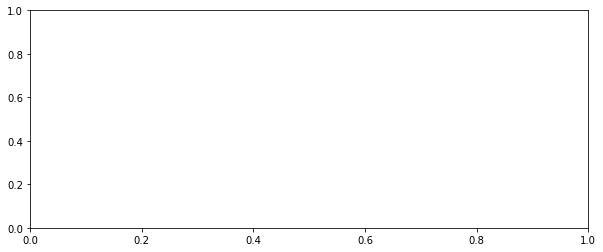

In [3]:
# Run pipeline
result = run_operando_pipeline(
    exp_dir=exp_dir,
    beamhistory_path=beamhistory_path,
    output_dir=output_dir,
    exposure_seconds=exposure_seconds,
    reference_dir=reference_dir,
    reference_beamhistory_path=reference_beamhistory_path,
    uncorrected_output_folder_name=uncorrected_output_folder_name,
    reference_bin_y=reference_bin_y,
    reference_bin_x=reference_bin_x,
    reference_final_subfolder=reference_final_subfolder,
)

beam_log = result["beam_log"]

df = pd.DataFrame(beam_log)

# Ensure time column is datetime and sorted
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time")

# Print first and last timestamps
first_time = df["time"].iloc[0]
last_time = df["time"].iloc[-1]
print("First image time :", first_time.strftime("%Y-%m-%d %H:%M:%S"))
print("Last image time  :", last_time.strftime("%Y-%m-%d %H:%M:%S"))

# Print directories
print("Corrected directory  :", result["corrected_dir"])
print("Uncorrected directory:", result["uncorrected_dir"])

# Plot beam history vs time
plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["relative_factor"], '.', markersize=3)

plt.xlabel("Time")
plt.ylabel("Beam / Reference (relative factor)")
plt.title("Beam intensity over time")
plt.grid(True)

plt.tight_layout()
plt.show()

In [4]:
print(df.columns)

Index(['run', 'time', 'beam_integral', 'relative_factor'], dtype='object')


In [5]:
print(df[:20])

                                                  run  \
0   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
1   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
2   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
3   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
4   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
5   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
6   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
7   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
8   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
9   exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
10  exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
11  exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
12  exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
13  exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
14  exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
15  exp1101_LiMetal_Cellgard_Asymmetric_2bar_cell1...   
16  exp1101_LiMetal_Cellgard_As

## Background Subtraction (Post-ImageJ)
 This section subtracts a background TIFF from the corrected images and writes intermediate and final outputs.


In [ ]:
background = compute_background_image(
    image_dir=result["corrected_dir"],
    n_images=20  # or omit → default = 15
)

import tifffile

bg_path = "background.tif"
tifffile.imwrite(bg_path, background.astype("float32"))

print("Saved background to:", bg_path)

In [4]:
from your_module import background_subtract_directory

corrected_dir = result["corrected_dir"]

final_dir = corrected_dir.replace("obint_corrected_", "final_")

background_subtract_directory(
    input_dir=corrected_dir,
    output_dir=final_dir,
    background_path=background_path,
)

Wrote: /data01/Leon_BOA_December2025/LiMetal/final_exp1101_LiMetal_Cellgard_Asymmetric_2bar


### The images should have been OB-corrected with the reference image. Before plotting, you may need to manually filter bright spots from TPX hot pixels.

# Plotting and Video

This section loads corrected images, extracts `MeanTPXModifiedTime` from TIFF tags, loads electrochemical data, then creates:
- A potential + image video
- A potential + thickness plot

In [48]:
# Plot/video settings
conv_thickness = 1.0
time_column = "time/s"
fps = 10
dt_seconds = 120
cmap = "inferno"
vmin = 0
vmax = 1.5
dpi = 150
merge_minutes = 1
merge_method = "mean"
roi_large = dict(r0=160, x0=221, y0=222)
potential_ylim=(-0.4, 1.0)

In [49]:
import tifffile
from datetime import datetime

def load_corrected_images_with_time(corrected_dir, tag_id=65002, r0=None, x0=None, y0=None):
    records = []
    for fname in sorted(os.listdir(corrected_dir)):
        path = os.path.join(corrected_dir, fname)
        if not os.path.isfile(path):
            continue
        # Try to open as TIFF (works even if no extension)
        try:
            with tifffile.TiffFile(path) as tif:
                img = tif.asarray()
                if r0 is not None and x0 is not None and y0 is not None:
                    y_start = max(0, y0 - r0)
                    y_end = min(img.shape[0], y0 + r0)
                    x_start = max(0, x0 - r0)
                    x_end = min(img.shape[1], x0 + r0)
                    img = img[y_start:y_end, x_start:x_end]
                tags = tif.pages[0].tags
                if tag_id not in tags:
                    continue
                dt_str = tags[tag_id].value
        except Exception:
            continue

        # Parse datetime
        try:
            dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S")
        except Exception:
            continue

        records.append((dt, img, path))

    records.sort(key=lambda x: x[0])
    img_datetimes = [r[0] for r in records]
    img_series = [r[1] for r in records]
    paths = [r[2] for r in records]
    return img_datetimes, img_series, paths


In [50]:
# Load final images (MeanTPXModifiedTime)
img_datetimes, img_series, img_paths = load_corrected_images_with_time(
    final_dir,
    tag_id=65002,
    r0=roi_large["r0"],
    x0=roi_large["x0"],
    y0=roi_large["y0"],
)


# Load electrochemical data
echem_datetimes, potential_series, echem_thickness_series = operando_plots.load_echem_data(
    echem_folder,
    conv_thickness=conv_thickness,
    time_column=time_column,
)

# Optionally merge images in time
img_datetimes, img_series = operando_plots.merge_images_by_time(
    img_datetimes, img_series, merge_minutes=merge_minutes, method=merge_method
)


In [51]:
###### Make potential + image video
operando_plots.make_potential_image_video_uniform_time(
    echem_datetimes=echem_datetimes,
    potential_series=potential_series,
    img_datetimes=img_datetimes,
    img_series=img_series,
    output_path=video_output_path,
    fps=fps,
    dt_seconds=dt_seconds,
    dpi=dpi,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    potential_ylim=potential_ylim,
    pixel_size=55,              # Pixel size in micrometers
    scalebar_length=5000,       # 5000 micrometers = 5 mm
    scale_label="5 mm",         # Label to display
    colorbar_label="Li thickness",
    cbar_n_ticks = 4,
    scalebar_color='white',     # White scale bar (visible on dark images)
    scale_fontsize=16,          # Font size
    scalebar_width_frac=0.02,   # Height of scale bar
    scalebar_position='lower left',  # Position
    scalebar_margin=0.05        # Margin from edge
)

## Capacity Events -> Neutron Image Indices
 Find capacity turning points/zeros, locate nearest neutron images, then plot them.


2025-12-07 12:09:46 ['zero'] -> image index 12
2025-12-07 13:14:46 ['turning'] -> image index 77
2025-12-07 13:17:54 ['turning'] -> image index 80
2025-12-07 13:17:54 ['turning'] -> image index 131
2025-12-07 14:09:31 ['turning'] -> image index 136
2025-12-07 14:09:31 ['turning'] -> image index 196
2025-12-07 14:14:31 ['turning'] -> image index 221
2025-12-07 15:14:21 ['turning'] -> image index 261
2025-12-07 15:14:31 ['turning'] -> image index 266
2025-12-07 15:14:31 ['turning'] -> image index 296
2025-12-07 15:14:41 ['turning'] -> image index 297
2025-12-07 16:19:41 ['turning'] -> image index 301
2025-12-07 16:59:54 ['turning'] -> image index 346
2025-12-07 16:59:54 ['turning'] -> image index 354
2025-12-07 17:04:54 ['turning'] -> image index 419


IndexError: index 8 is out of bounds for axis 0 with size 8

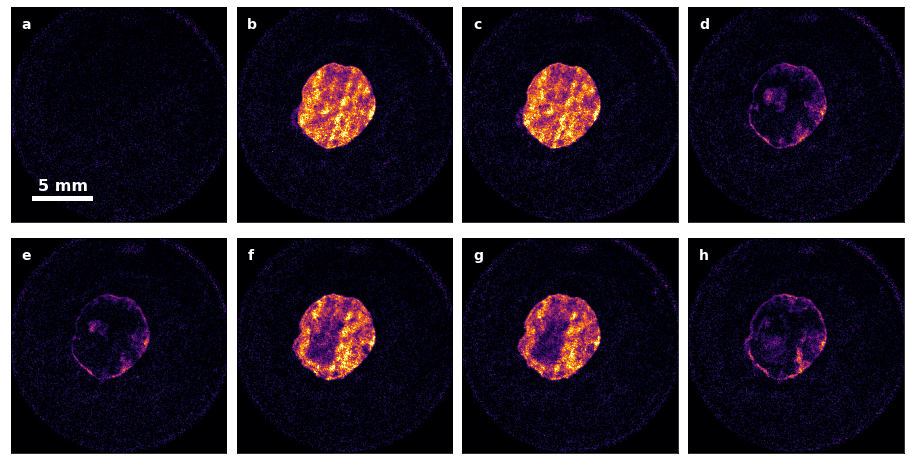

In [52]:
# === Capacity event images ===
from datetime import timedelta
import importlib.util
import os

pixel_size = 55
show_labels = True
label_start = 0  # used by potential-plot labeling

# Color bar
cmap = "inferno"
cbar_ranges = [(0, 3)]
cbar_length_frac = 0.8
cbar_mode = "shared right"
cbar_fontsize = 16
cbar_unit = ["μm"]
# cbar_width_frac = 0.01
cbar_show_ticklines = True

# Scale bar
scale_fontsize = 16
scalebar_mode = "outside left"
scalebar_length = 5000
scale_label = "5 mm"
scalebar_width_frac = 0.5

# Figure layout
spacing = (0.05, 0)
figsize = (16, 4)
ncols = 4
nrows = 2

# Defaults so downstream cells never fail
events = []
img_indices = []
event_times = []
event_times_for_plot = []

# Restrict capacity to image time range
if len(img_datetimes) == 0:
    raise ValueError("No image timestamps found. Check corrected image metadata.")

img_start = min(img_datetimes)
img_end = max(img_datetimes)

cap_times = []
cap_values = []
for t, c in zip(echem_datetimes, echem_thickness_series / conv_thickness):
    if img_start <= t <= img_end:
        cap_times.append(t)
        cap_values.append(c)

if len(cap_times) == 0:
    print("No capacity data within image time range.")
else:
    # Capacity events (turning points + zeros)
    events = operando_data.find_capacity_turning_points_and_zeros(
        cap_times,
        capacity_series=cap_values,
        only_initial_zero=True,
    )

if not events:
    print("No capacity events found.")
else:
    event_times = [e["time"] for e in events]
    img_indices = operando_data.find_nearest_image_indices(event_times, img_datetimes)

    # Use plotted-image timestamps for potential labels, shifted by -1 minute
    event_times_for_plot = [img_datetimes[idx] - timedelta(minutes=1) for idx in img_indices]

    for e, idx in zip(events, img_indices):
        print("{} {} -> image index {}".format(e["time"], e["labels"], idx))

    # Plot images at these indices
    plots_path = os.path.join(os.path.join(pipeline_dir, "plots", "plots.py"))
    plots_spec = importlib.util.spec_from_file_location("plots_mod", plots_path)
    plots_mod = importlib.util.module_from_spec(plots_spec)
    plots_spec.loader.exec_module(plots_mod)

    fig, axes = plots_mod.plot_images(
        img_series=img_series,
        img_indices=img_indices,
        pixel_size=55,
        show_labels=True,

        # Color bar
        cmap="inferno",
        cbar_ranges=[(0, 3)],
        cbar_shared_length=0.6,
        cbar_mode="shared left",
        cbar_fontsize=16,
        cbar_unit=["μm"],
        cbar_width_frac=0.015,
        cbar_show_ticklines=True,
        cbar_n_ticks=4,
        cbar_pad=0.02,

        # Scale bar
        scale_fontsize=16,
        scalebar_mode="inside",
        scalebar_length=5000,
        scale_label="5 mm",
        scalebar_width_frac=0.02,

        # Figure layout
        spacing=(0.05, 0),
        figsize=(16, 8.5),
        ncols=4,
        nrows=2,
    )


/data01/data_acquisition/scripts/toolbox/operando/operando plots.py:801: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(roi_values)


Kept event indices (in event list): [0, 2, 4, 5, 8, 13, 14]
Corresponding FULL image indices: [11, 79, 135, 195, 265, 353, 418]

AVERAGE THICKNESS AT SELECTED EVENTS
Event a:
  Event time:      2025-12-07 12:08:28
  Closest image:   2025-12-07 12:08:28
  Time difference: 0.0 seconds
  Avg thickness:   0.2030
  Image index:     11

Event b:
  Event time:      2025-12-07 13:16:52
  Closest image:   2025-12-07 13:16:52
  Time difference: 0.0 seconds
  Avg thickness:   0.4001
  Image index:     79

Event c:
  Event time:      2025-12-07 14:13:12
  Closest image:   2025-12-07 14:13:12
  Time difference: 0.0 seconds
  Avg thickness:   0.1260
  Image index:     135

Event d:
  Event time:      2025-12-07 15:13:33
  Closest image:   2025-12-07 15:13:33
  Time difference: 0.0 seconds
  Avg thickness:   0.3566
  Image index:     195

Event e:
  Event time:      2025-12-07 17:03:49
  Closest image:   2025-12-07 17:03:49
  Time difference: 0.0 seconds
  Avg thickness:   0.1293
  Image index:     2

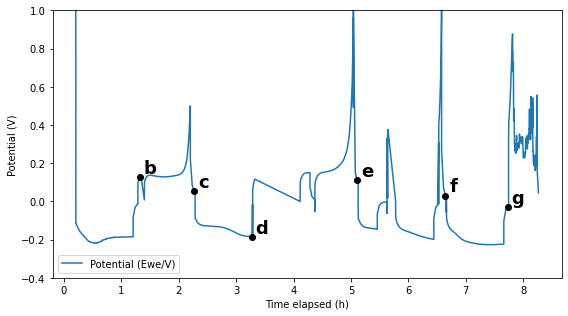

Image saved to: /data01/Leon_BOA_December2025/LiMetal/potential_exp1101_LiMetal_Cellgard_Asymmetric_2bar.png


<Figure size 432x288 with 0 Axes>

In [76]:
# Make potential + thickness plot (image-derived thickness)
import os
import matplotlib.pyplot as plt
from datetime import timedelta
import numpy as np

roi_small = dict(r0=111, x0=221, y0=222)
avg_thickness_series = operando_plots.circular_average_thickness_series(
    img_series, **roi_small
)

# Optional event labels (prefer timestamps prepared in capacity-event cell)
event_times_for_plot = globals().get("event_times_for_plot", None)
if event_times_for_plot is None:
    img_indices_local = globals().get("img_indices", [])
    event_times_for_plot = [img_datetimes[idx] - timedelta(minutes=1) for idx in img_indices_local]

label_start = globals().get("label_start", 0)


# Define which events to exclude (0-based indexing)
exclude_indices = [1, 3, 6, 7, 9, 10, 11, 12]  

# Filter the event times AND get the corresponding FULL image indices
filtered_event_times = []
filtered_event_indices = []  # Original event indices (indices into event_times_for_plot)
filtered_image_indices = []  # ACTUAL IMAGE INDICES in the full img_series (0-499)

for i, event_time in enumerate(event_times_for_plot):
    if i not in exclude_indices:
        filtered_event_times.append(event_time)
        filtered_event_indices.append(i)
        
        # Find the closest image in the FULL image sequence
        time_diffs = np.array([abs((t - event_time).total_seconds()) for t in img_datetimes])
        closest_img_idx = np.argmin(time_diffs)
        filtered_image_indices.append(closest_img_idx)  # This is the full image index!

print(f"Kept event indices (in event list): {filtered_event_indices}")
print(f"Corresponding FULL image indices: {filtered_image_indices}")

# --- CREATE OUTPUT DIRECTORY AND TEXT FILE ---
out_dir = os.path.join(base_dir, "LiMetal")
os.makedirs(out_dir, exist_ok=True)
out_text_path = os.path.join(out_dir, "thickness_values.txt")

# --- EXPORT THICKNESS VALUES TO TEXT FILE ---
def print_and_save(message, file_handle):
    print(message)
    file_handle.write(message + "\n")

with open(out_text_path, 'w') as f:
    print_and_save("\n" + "="*60, f)
    print_and_save("AVERAGE THICKNESS AT SELECTED EVENTS", f)
    print_and_save("="*60, f)
    
    thickness_values = []
    for i, event_time in enumerate(filtered_event_times):
        # Find closest image time
        time_diffs = np.array([abs((t - event_time).total_seconds()) for t in img_datetimes])
        closest_idx = np.argmin(time_diffs)
        
        # Get the thickness value
        thickness_value = avg_thickness_series[closest_idx]
        thickness_values.append(thickness_value)
        
        # Get the event label (a, b, c, ...)
        event_label = chr(97 + int(label_start) + i)
        
        # Format the time nicely
        event_time_str = event_time.strftime('%Y-%m-%d %H:%M:%S')
        closest_time_str = img_datetimes[closest_idx].strftime('%Y-%m-%d %H:%M:%S')
        time_diff_seconds = time_diffs[closest_idx]
        
        print_and_save(f"Event {event_label}:", f)
        print_and_save(f"  Event time:      {event_time_str}", f)
        print_and_save(f"  Closest image:   {closest_time_str}", f)
        print_and_save(f"  Time difference: {time_diff_seconds:.1f} seconds", f)
        print_and_save(f"  Avg thickness:   {thickness_value:.4f}", f)
        print_and_save(f"  Image index:     {closest_idx}", f)
        print_and_save("", f)
    
    # Also print summary statistics
    print_and_save("-"*60, f)
    print_and_save("SUMMARY:", f)
    print_and_save(f"  ROI: center=({roi_small['x0']}, {roi_small['y0']}), radius={roi_small['r0']} pixels", f)
    print_and_save(f"  Total original events: {len(event_times_for_plot)}", f)
    print_and_save(f"  Excluded indices: {exclude_indices}", f)
    print_and_save(f"  Number of kept events: {len(filtered_event_times)}", f)
    if thickness_values:
        print_and_save(f"  Thickness range:  {np.min(thickness_values):.4f} to {np.max(thickness_values):.4f}", f)
        print_and_save(f"  Mean thickness:   {np.mean(thickness_values):.4f}", f)
        print_and_save(f"  Std thickness:    {np.std(thickness_values):.4f}", f)
    print_and_save("="*60 + "\n", f)

print(f"Text output saved to: {out_text_path}")
# ---------------------------------------------

operando_plots.plot_potential_and_thickness(
    echem_datetime_series=echem_datetimes,
    potential_series=potential_series,
    echem_thickness_series=echem_thickness_series,
    img_datetime_series=img_datetimes,
    avg_thickness_series=avg_thickness_series,
    potential_ylim=potential_ylim,
    event_times=filtered_event_times,
    label_start=label_start,
    event_marker_size=6,
    event_label_fontsize=18,
)

# Save figure safely
fig = plt.gcf()
out_path = os.path.join(base_dir, "LiMetal", "potential_exp1101_LiMetal_Cellgard_Asymmetric_2bar.png")
os.makedirs(os.path.dirname(out_path), exist_ok=True)
fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"Image saved to: {out_path}")

# Now filtered_image_indices contains the indices into the FULL img_series (0-499)
# These can be used directly with img_series[filtered_image_indices[0]], etc.

2025-12-07 12:09:46 ['zero'] -> image index 12
2025-12-07 13:14:46 ['turning'] -> image index 77
2025-12-07 13:17:54 ['turning'] -> image index 80
2025-12-07 13:17:54 ['turning'] -> image index 131
2025-12-07 14:09:31 ['turning'] -> image index 136
2025-12-07 14:09:31 ['turning'] -> image index 196
2025-12-07 14:14:31 ['turning'] -> image index 221
2025-12-07 15:14:21 ['turning'] -> image index 261
2025-12-07 15:14:31 ['turning'] -> image index 266
2025-12-07 15:14:31 ['turning'] -> image index 296
2025-12-07 15:14:41 ['turning'] -> image index 297
2025-12-07 16:19:41 ['turning'] -> image index 301
2025-12-07 16:59:54 ['turning'] -> image index 346
2025-12-07 16:59:54 ['turning'] -> image index 354
2025-12-07 17:04:54 ['turning'] -> image index 419
Saved: /data01/Leon_BOA_December2025/LiMetal/nci_exp1101_LiMetal_Cellgard_Asymmetric_2bar.png


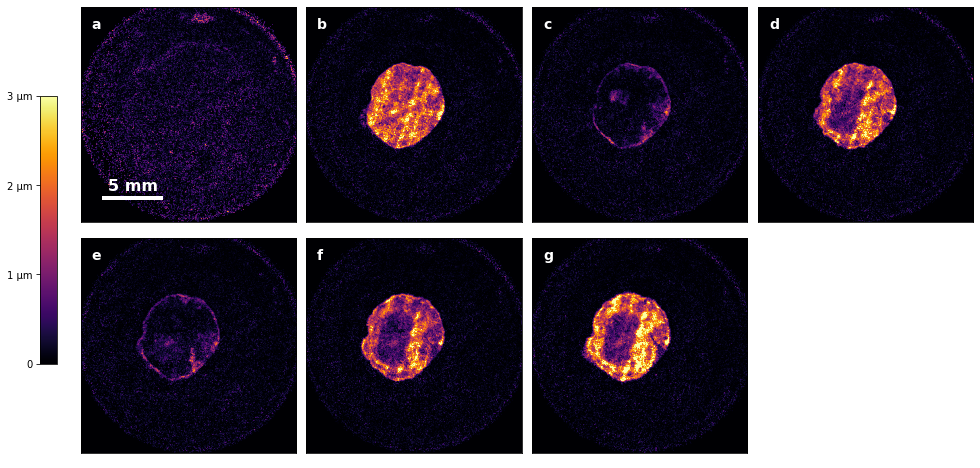

In [73]:
# === Capacity event images ===
from datetime import timedelta
import importlib.util
import os

pixel_size = 55
show_labels = True
label_start = 0  # used by potential-plot labeling

# Color bar
cmap = "inferno"
cbar_ranges = [(0, 3)]
cbar_length_frac = 0.8
cbar_mode = "shared right"
cbar_fontsize = 16
cbar_unit = ["μm"]
# cbar_width_frac = 0.01
cbar_show_ticklines = True

# Scale bar
scale_fontsize = 16
scalebar_mode = "outside left"
scalebar_length = 5000
scale_label = "5 mm"
scalebar_width_frac = 0.5

# Figure layout
spacing = (0.05, 0)
figsize = (16, 4)
ncols = 4
nrows = 2

# Defaults so downstream cells never fail
events = []
img_indices = []
event_times = []
event_times_for_plot = []

# Restrict capacity to image time range
if len(img_datetimes) == 0:
    raise ValueError("No image timestamps found. Check corrected image metadata.")

img_start = min(img_datetimes)
img_end = max(img_datetimes)

cap_times = []
cap_values = []
for t, c in zip(echem_datetimes, echem_thickness_series / conv_thickness):
    if img_start <= t <= img_end:
        cap_times.append(t)
        cap_values.append(c)

if len(cap_times) == 0:
    print("No capacity data within image time range.")
else:
    # Capacity events (turning points + zeros)
    events = operando_data.find_capacity_turning_points_and_zeros(
        cap_times,
        capacity_series=cap_values,
        only_initial_zero=True,
    )

if not events:
    print("No capacity events found.")
else:
    event_times = [e["time"] for e in events]
    img_indices = operando_data.find_nearest_image_indices(event_times, img_datetimes)

    # Use plotted-image timestamps for potential labels, shifted by -1 minute
    event_times_for_plot = [img_datetimes[idx] - timedelta(minutes=1) for idx in img_indices]

    for e, idx in zip(events, img_indices):
        print("{} {} -> image index {}".format(e["time"], e["labels"], idx))

    # Plot images at these indices
    plots_path = os.path.join(os.path.join(pipeline_dir, "plots", "plots.py"))
    plots_spec = importlib.util.spec_from_file_location("plots_mod", plots_path)
    plots_mod = importlib.util.module_from_spec(plots_spec)
    plots_spec.loader.exec_module(plots_mod)

    fig, axes = plots_mod.plot_images(
        img_series=img_series,
        img_indices=filtered_image_indices,
        pixel_size=55,
        show_labels=True,

        # Color bar
        cmap="inferno",
        cbar_ranges=[(0, 3)],
        cbar_shared_length=0.6,
        cbar_mode="shared left",
        cbar_fontsize=16,
        cbar_unit=["μm"],
        cbar_width_frac=0.015,
        cbar_show_ticklines=True,
        cbar_n_ticks=4,
        cbar_pad=0.02,

        # Scale bar
        scale_fontsize=16,
        scalebar_mode="inside",
        scalebar_length=5000,
        scale_label="5 mm",
        scalebar_width_frac=0.02,

        # Figure layout
        spacing=(0.05, 0),
        figsize=(16, 8.5),
        ncols=4,
        nrows=2,
    )

    # Save figure safely
    out_path = os.path.join(base_dir, "LiMetal", "nci_exp1101_LiMetal_Cellgard_Asymmetric_2bar.png")
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved: {out_path}")
